In [ ]:
r"C:\Users\admin\Downloads\Air Quality.csv"

In [46]:
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col,when
from pyspark.sql.types import FloatType
import matplotlib.pyplot as plt
import pandas as pd

# Create a SparkSession
spark = SparkSession.builder.appName("AirQualityAnalysis").getOrCreate()

In [33]:
# Load the dataset
# Make sure to replace 'your_dataset.csv' with the actual path to your file
df = spark.read.csv(r"C:\Users\admin\Downloads\Air Quality.csv", header=True, inferSchema=True)

# Replace 'NA' with null and then cast to float
for col_name in ["pollutant_min", "pollutant_max", "pollutant_avg"]:
    df = df.withColumn(col_name, 
                       when(col(col_name) == 'NA', None).otherwise(col(col_name)).cast(FloatType()))

# Drop rows with null values in key columns
df_cleaned = df.na.drop(subset=["pollutant_avg", "pollutant_id", "state"])

# Print the schema and show a preview
df_cleaned.printSchema()
df_cleaned.show(5)

root
 |-- country: string (nullable = true)
 |-- state: string (nullable = true)
 |-- city: string (nullable = true)
 |-- station: string (nullable = true)
 |-- last_update: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- pollutant_id: string (nullable = true)
 |-- pollutant_min: float (nullable = true)
 |-- pollutant_max: float (nullable = true)
 |-- pollutant_avg: float (nullable = true)

+-------+--------------+-----------------+--------------------+-------------------+----------+----------+------------+-------------+-------------+-------------+
|country|         state|             city|             station|        last_update|  latitude| longitude|pollutant_id|pollutant_min|pollutant_max|pollutant_avg|
+-------+--------------+-----------------+--------------------+-------------------+----------+----------+------------+-------------+-------------+-------------+
|  India|Andhra_Pradesh|         Chittoor|Gangineni Cheruvu.

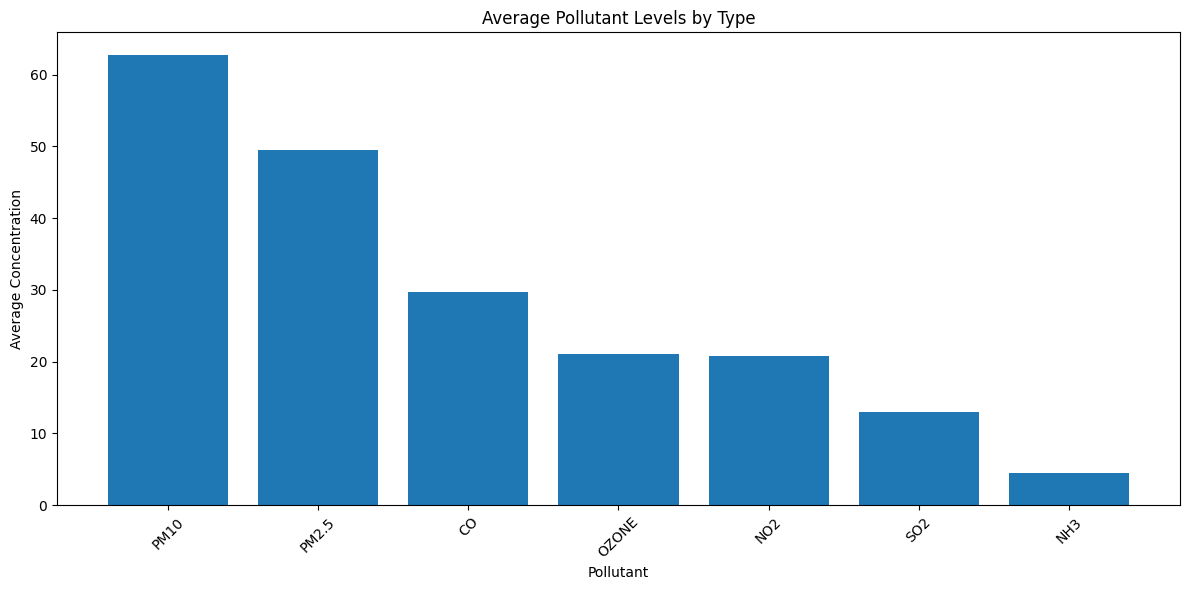

In [34]:
# 1. Average pollutant level by pollutant type
pollutant_avg = df_cleaned.groupBy("pollutant_id").avg("pollutant_avg").toPandas()
pollutant_avg = pollutant_avg.sort_values('avg(pollutant_avg)', ascending=False)

plt.figure(figsize=(12, 6))
plt.bar(pollutant_avg["pollutant_id"], pollutant_avg["avg(pollutant_avg)"])
plt.xlabel("Pollutant")
plt.ylabel("Average Concentration")
plt.title("Average Pollutant Levels by Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

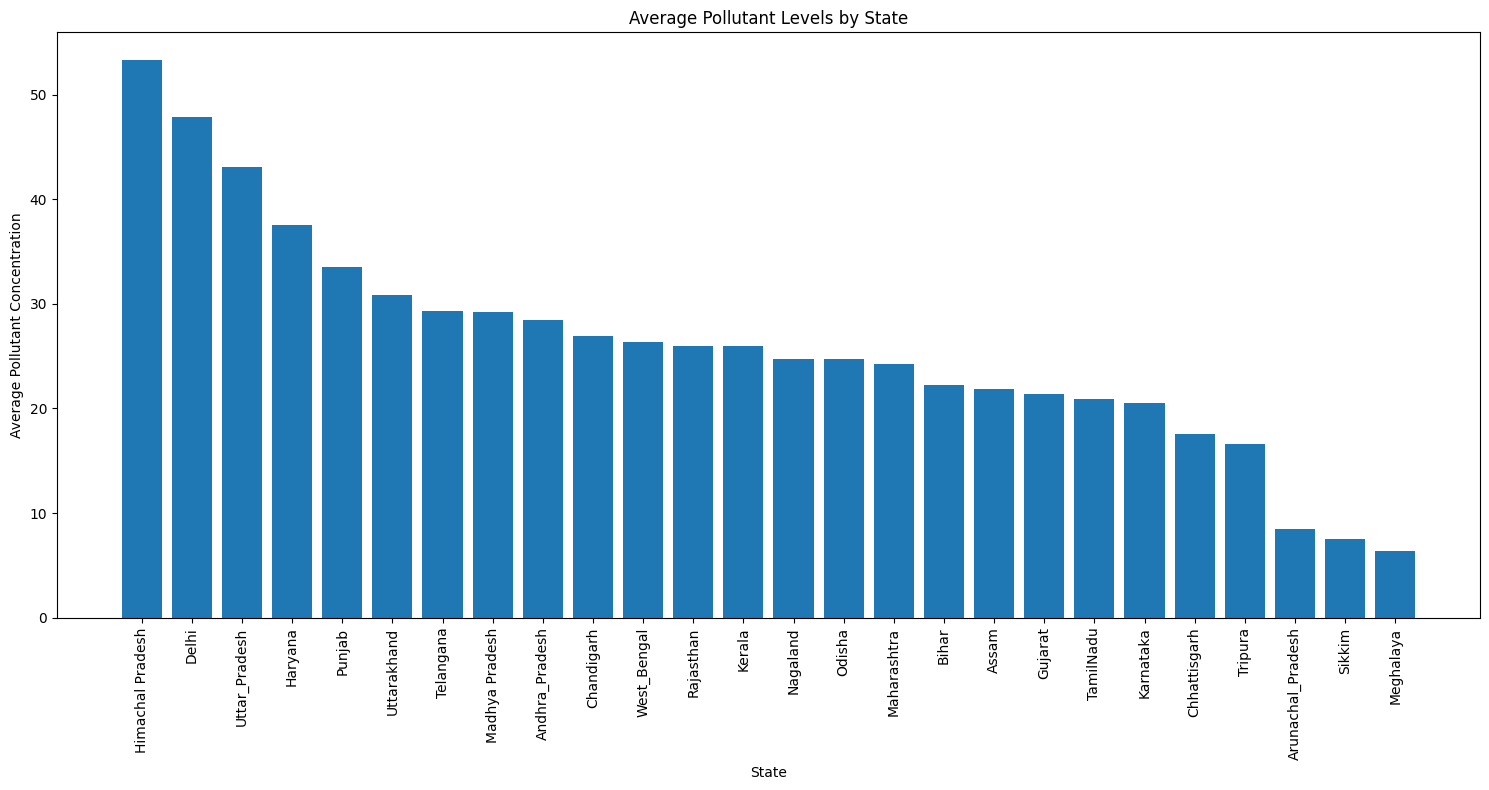

In [35]:
# 2. Average pollutant level by state
state_avg = df_cleaned.groupBy("state").avg("pollutant_avg").toPandas()
state_avg = state_avg.sort_values('avg(pollutant_avg)', ascending=False)

plt.figure(figsize=(15, 8))
plt.bar(state_avg["state"], state_avg["avg(pollutant_avg)"])
plt.xlabel("State")
plt.ylabel("Average Pollutant Concentration")
plt.title("Average Pollutant Levels by State")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

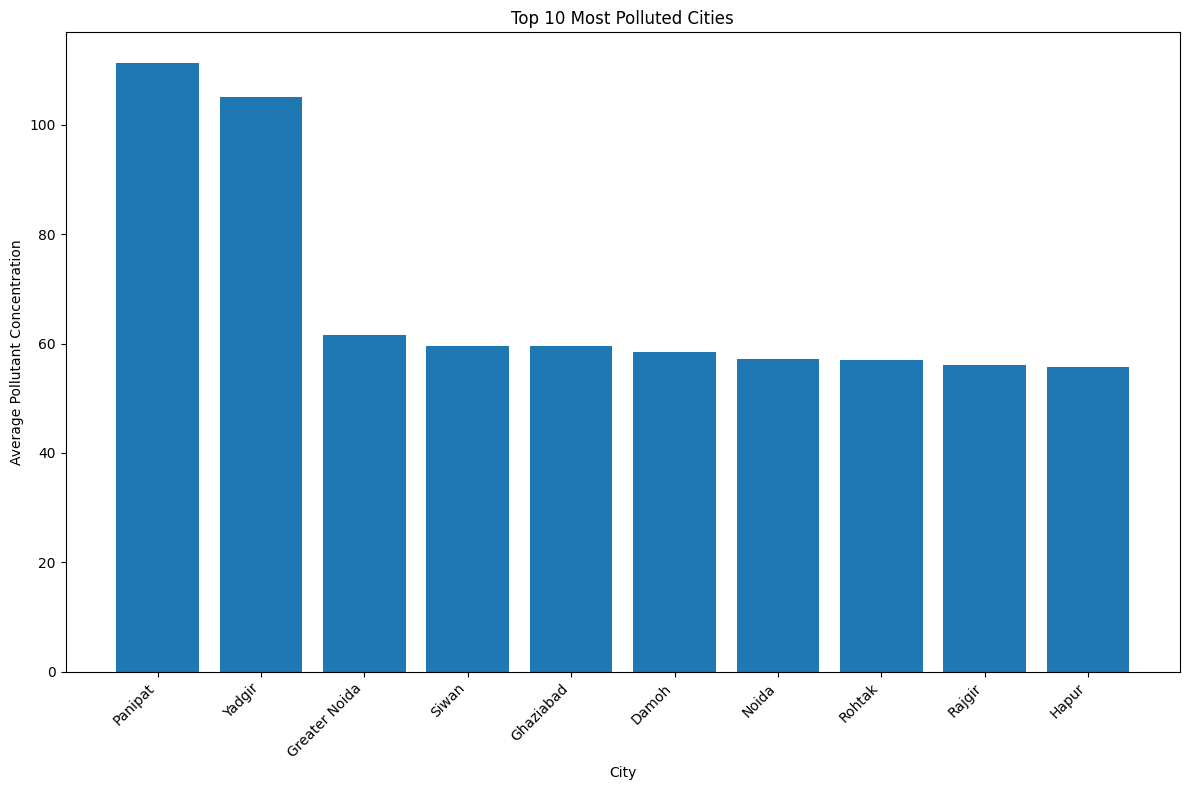

In [36]:
from pyspark.sql.functions import desc

# Calculate the average pollutant level for each city
city_avg = df_cleaned.groupBy("city").avg("pollutant_avg").toPandas()

# Sort and get the top 10
top_10_cities = city_avg.sort_values('avg(pollutant_avg)', ascending=False).head(10)

# Create the plot
plt.figure(figsize=(12, 8))
plt.bar(top_10_cities["city"], top_10_cities["avg(pollutant_avg)"])
plt.xlabel("City")
plt.ylabel("Average Pollutant Concentration")
plt.title("Top 10 Most Polluted Cities")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

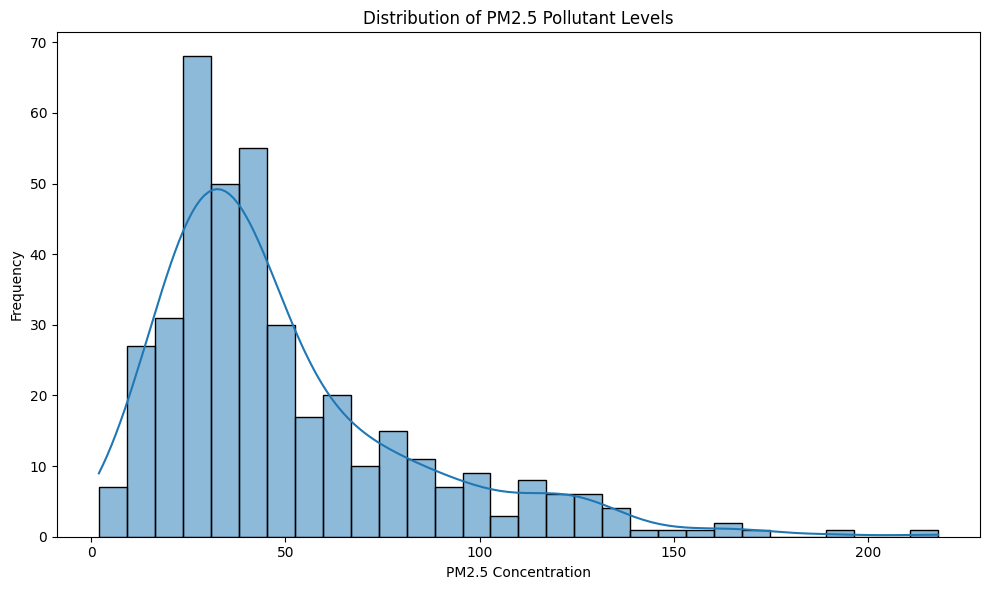

In [37]:
# Filter the DataFrame to include only PM2.5 data
pm25_df = df_cleaned.filter(col("pollutant_id") == "PM2.5").toPandas()

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(pm25_df['pollutant_avg'], bins=30, kde=True)
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.title("Distribution of PM2.5 Pollutant Levels")
plt.tight_layout()
plt.show()

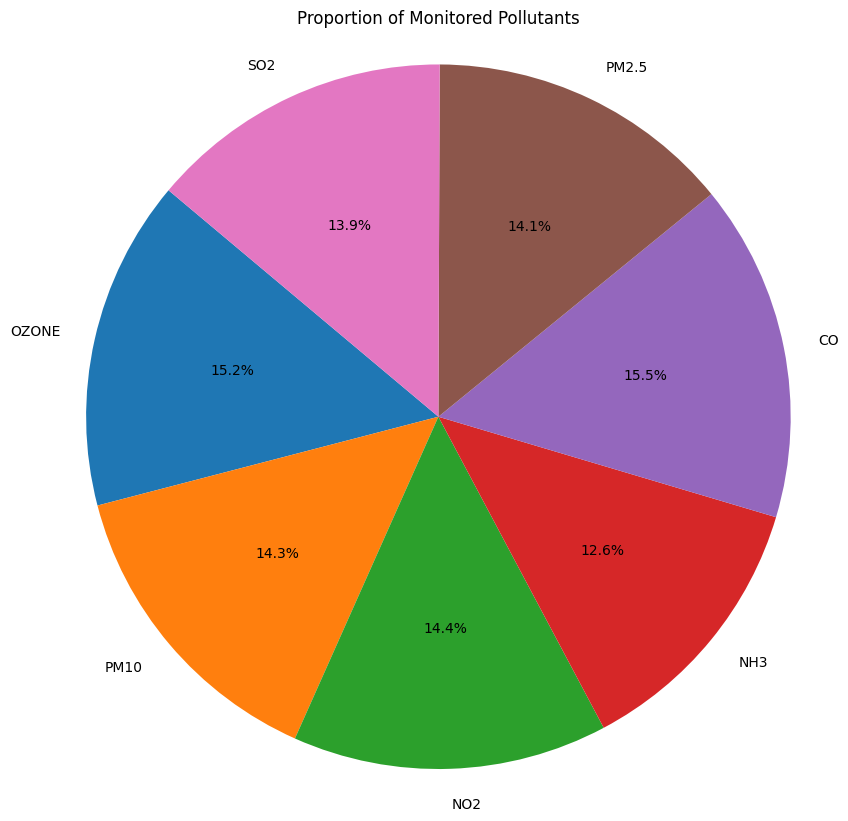

In [38]:
# Count the occurrences of each pollutant
pollutant_counts = df_cleaned.groupBy("pollutant_id").count().toPandas()

# Create the pie chart
plt.figure(figsize=(10, 10))
plt.pie(pollutant_counts["count"], labels=pollutant_counts["pollutant_id"], autopct='%1.1f%%', startangle=140)
plt.title("Proportion of Monitored Pollutants")
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

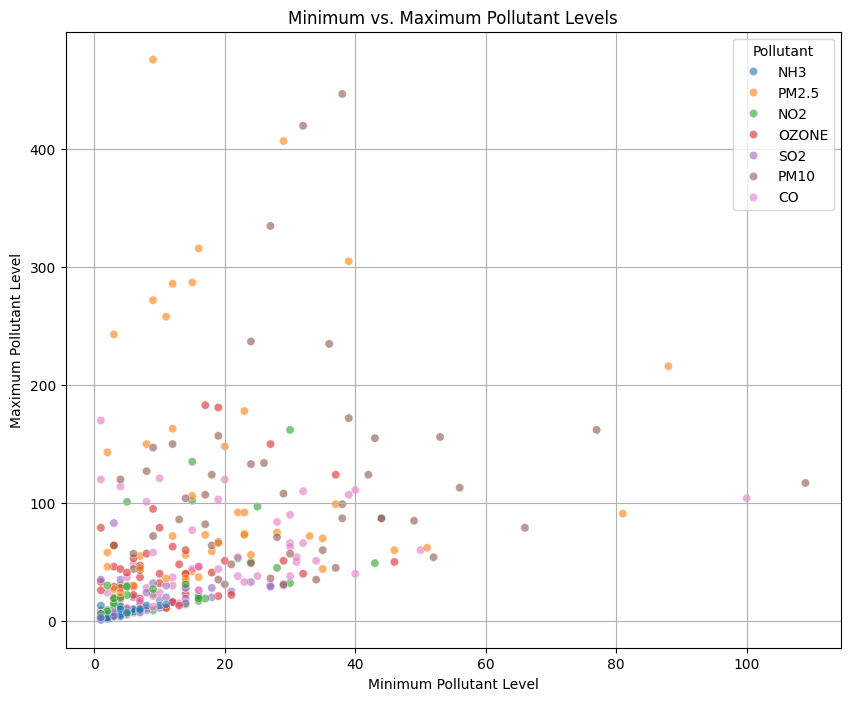

In [41]:
# Sample the data to make the plot more readable
scatter_data = df_cleaned.sample(withReplacement=False, fraction=0.1, seed=42).toPandas()

# Create the scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(data=scatter_data, x="pollutant_min", y="pollutant_max", hue="pollutant_id", alpha=0.6)
plt.title("Minimum vs. Maximum Pollutant Levels")
plt.xlabel("Minimum Pollutant Level")
plt.ylabel("Maximum Pollutant Level")
plt.legend(title="Pollutant")
plt.grid(True)
plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_10044\2506618564.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_data, x="pollutant_id", y="pollutant_avg", palette="muted")


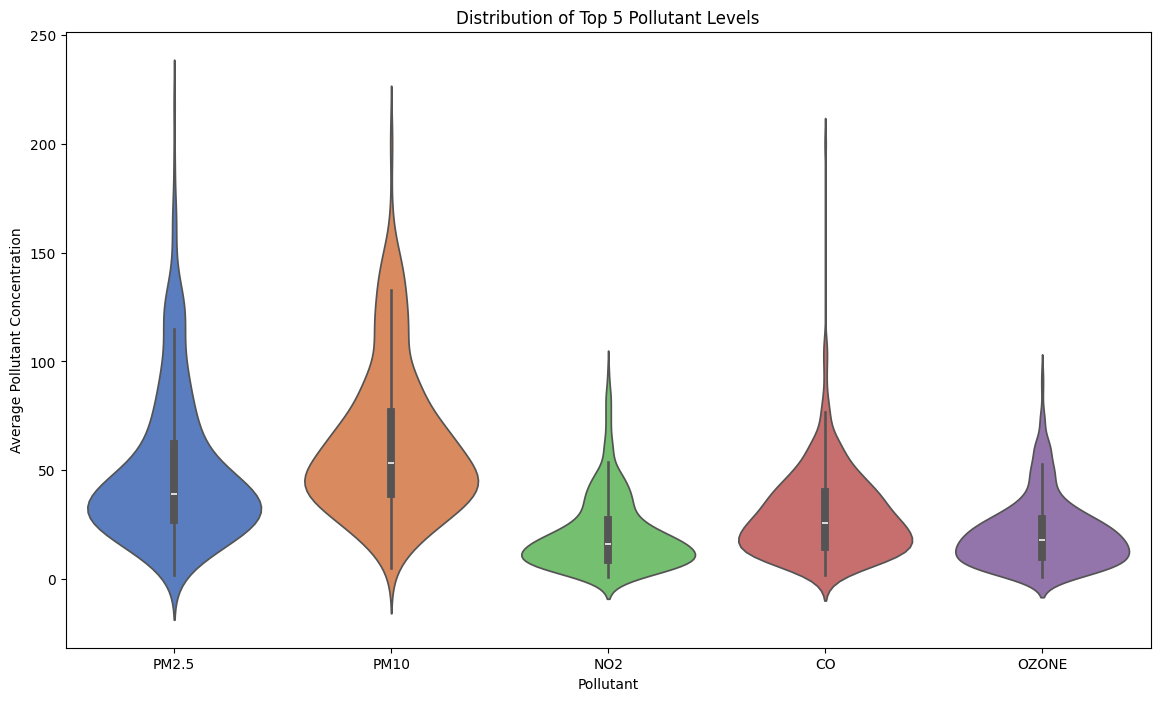

In [42]:
# Get the top 5 most frequent pollutants for a cleaner plot
top_pollutants = [row['pollutant_id'] for row in df_cleaned.groupBy("pollutant_id").count().orderBy(col("count").desc()).take(5)]
violin_data = df_cleaned.filter(col("pollutant_id").isin(top_pollutants)).toPandas()


# Create the violin plot
plt.figure(figsize=(14, 8))
sns.violinplot(data=violin_data, x="pollutant_id", y="pollutant_avg", palette="muted")
plt.title("Distribution of Top 5 Pollutant Levels")
plt.xlabel("Pollutant")
plt.ylabel("Average Pollutant Concentration")
plt.show()